# Solution Set: Hands-on Reinforcement Learning (RL), Take-home Exercises

**Course Name:** Executive Training Programme on Trustworthy AI for DRDO Scientists

**Instructor:** Dr. Sabyasachi Mukhopadhyay, Department of Computer Science and Engineering, IIT Kharagpur

**Companion to:** *Hands-on Reinforcement Learning (RL): From Bandits to Deep Q-Networks*

## What this notebook contains

| Exercise | Question | Method used in the solution |
|---|---|---|
| 0 | "Try it" from Part 4: change `alpha` to 0.5 or `episodes` to 5,000 | Re-run Q-learning with each change and compare the curves and success rates |
| 1 | Re-run Value Iteration with `gamma=0.9` | Compare values, policy, success rate and episode length for $\gamma = 0.99$ and $\gamma = 0.9$ |
| 2 | Q-learning on deterministic ice (`is_slippery=False`) | Track the greedy policy during training to see when it first solves the lake |
| 3 | SARSA instead of Q-learning | Implement both in one function that differs in a single line; compare on FrozenLake and on CliffWalking |
| 4 | Double Deep Q-Network (DQN) | Add Double DQN to `train_dqn`; compare stability, test returns and Q-value overestimation over two seeds |
| 5 | DQN on `Acrobot-v1` | Re-use the same DQN code on a 6-dimensional state with 3 actions |

## How to use this notebook

* It is **self-contained**: it re-defines every function it needs, so it does not depend on the main notebook having been run.
* Run the cells **in order** with `Shift + Enter`. A Central Processing Unit (CPU) runtime is enough.
* Every code cell is followed by a **Reading the output** section that interprets the results printed in this run. With the fixed seed your numbers should be the same or very close; other library versions can shift them slightly.
* Try each exercise yourself first, then compare your answer with the solution.

---
# Setup: libraries and the functions from the main notebook

The functions below are the same as in the main notebook, with two small additions that do not change their behaviour: `q_learning` can optionally record the greedy policy's success rate during training (for Exercise 2), and a `show_policy` helper prints a policy as arrows.

In [1]:
!pip install -q gymnasium

In [2]:
import copy                        # deep copies of network weights (used to keep the best DQN checkpoint)
import random                      # Python's built-in random module, used for epsilon-greedy coin flips
import time                        # used to measure how long training takes
from collections import deque      # a fast double-ended queue, used as the replay buffer

import numpy as np                 # numerical arrays, maths and random numbers
import matplotlib.pyplot as plt    # plotting learning curves and value maps
import gymnasium as gym            # the RL environments
import torch                       # deep-learning library (Exercises 4 and 5)
import torch.nn as nn              # neural-network building blocks
import torch.optim as optim        # optimisers such as Adam

SEED = 42                          # same seed as the main notebook
random.seed(SEED)                  # seed Python's random generator
np.random.seed(SEED)               # seed NumPy's random generator
torch.manual_seed(SEED)            # seed PyTorch's random generator
plt.rcParams["figure.figsize"] = (8, 4)   # default plot size

ARROWS = np.array(["←", "↓", "→", "↑"])  # symbols for FrozenLake actions 0, 1, 2, 3


def make_lake(slippery=True):
    # Create the 4x4 FrozenLake environment, slippery or deterministic
    return gym.make("FrozenLake-v1", map_name="4x4", is_slippery=slippery)


def value_iteration(P, n_states, n_actions, gamma=0.99, theta=1e-8):
    # Optimal values V* and a greedy optimal policy from the Bellman optimality equation (same as Part 3)
    V = np.zeros(n_states)                          # all values start at 0
    sweeps = 0                                      # number of full passes over the states
    while True:                                     # repeat until the values converge
        delta = 0.0                                 # largest change during this sweep
        for s in range(n_states):                   # update every state
            q = np.zeros(n_actions)                 # value of each action in s
            for a in range(n_actions):              # every action ...
                for prob, s2, r, term in P[s][a]:   # ... and every possible outcome
                    q[a] += prob * (r + gamma * V[s2] * (not term))  # expected reward + discounted next value
            delta = max(delta, abs(q.max() - V[s]))  # track the change
            V[s] = q.max()                          # Bellman optimality: best action's value
        sweeps += 1                                 # one more sweep
        if delta < theta:                           # converged
            break
    policy = np.zeros(n_states, dtype=int)          # greedy policy from the final values
    for s in range(n_states):                       # for every state ...
        q = [sum(p * (r + gamma * V[s2] * (not t)) for p, s2, r, t in P[s][a]) for a in range(n_actions)]
        policy[s] = int(np.argmax(q))               # ... the action with the highest expected value
    return V, policy, sweeps                        # values, policy, sweeps needed


def evaluate_policy(env, policy, episodes=2000, seed=SEED):
    # Success rate of a fixed tabular policy (same as Part 3)
    successes = 0                                   # episodes that reached the goal
    for i in range(episodes):                       # many independent episodes
        s, _ = env.reset(seed=seed + i)             # a different seed for each episode
        done = False                                # end-of-episode flag
        while not done:                             # follow the policy
            s, r, term, trunc, _ = env.step(int(policy[s]))  # act
            done = term or trunc                    # hole, goal or the 100-step limit
        successes += r                              # reward is 1 only at the goal
    return successes / episodes                     # success rate between 0 and 1


def q_learning(env, episodes=20000, alpha=0.1, gamma=0.99, eps_start=1.0, eps_end=0.01,
               eps_decay_frac=0.6, seed=SEED, eval_env=None, eval_every=0, eval_episodes=100):
    # Tabular Q-learning (same as Part 4). Optional: every eval_every episodes, measure the greedy policy
    rng = np.random.default_rng(seed)               # random generator for exploration
    Q = np.zeros((env.observation_space.n, env.action_space.n))  # the Q-table
    rewards = np.zeros(episodes)                    # 1 if the episode reached the goal
    history = []                                    # (episode, greedy success rate) pairs, if tracking
    decay_episodes = int(eps_decay_frac * episodes) # episodes over which epsilon falls to eps_end
    for ep in range(episodes):                      # one training episode per iteration
        eps = max(eps_end, eps_start - (eps_start - eps_end) * ep / decay_episodes)  # current epsilon
        s, _ = env.reset(seed=seed + ep)            # new episode
        done = False                                # end flag
        while not done:                             # interact until the episode ends
            if rng.random() < eps:                  # explore ...
                a = int(rng.integers(env.action_space.n))          # ... random action
            else:                                   # exploit ...
                a = int(rng.choice(np.flatnonzero(Q[s] == Q[s].max())))  # ... best action, random tie-break
            s2, r, term, trunc, _ = env.step(a)     # act
            target = r + gamma * np.max(Q[s2]) * (not term)   # TD target
            Q[s, a] += alpha * (target - Q[s, a])   # TD update
            s = s2                                  # move on
            done = term or trunc                    # check for the end
        rewards[ep] = r                             # record success or failure
        if eval_every and (ep + 1) % eval_every == 0:   # optional greedy evaluation (does not touch rng)
            history.append((ep + 1, evaluate_policy(eval_env, np.argmax(Q, axis=1), eval_episodes)))
    return Q, rewards, history                      # Q-table, training rewards, evaluation history


def show_policy(policy, desc):
    # Print a 4x4 policy as arrows, with H for holes and G for the goal
    for row in range(4):                            # one line per row
        print("  " + " ".join(desc[row, c] if desc[row, c] in "HG" else ARROWS[policy[row * 4 + c]]
                              for c in range(4)))


lake = make_lake(slippery=True)                     # the slippery lake used in Parts 3 and 4
P = lake.unwrapped.P                                # its transition model
desc = lake.unwrapped.desc.astype(str)              # map letters as a 4x4 array
n_states, n_actions = lake.observation_space.n, lake.action_space.n  # 16 states, 4 actions
print("Gymnasium", gym.__version__, "| PyTorch", torch.__version__, "| setup complete")

Gymnasium 1.4.0 | PyTorch 2.15.0+cu132 | setup complete


#### Reading the output

One line confirms that the libraries loaded and that every helper function is defined. Nothing is trained yet. (The PyTorch build string may end in `+cpu` or `+cu…` depending on the runtime; this does not affect any result here.)

---
# Exercise 0. "Try it" from Part 4: learning rate and training length

**Question:** change `alpha` to 0.5, or `episodes` to 5,000, and re-run the Q-learning cells. What happens to the success rate and to the smoothness of the curve?

**Approach:** train three agents with the same seed: the baseline from the main notebook ($\alpha = 0.1$, 20,000 episodes), a high learning rate ($\alpha = 0.5$, 20,000 episodes) and a short run ($\alpha = 0.1$, 5,000 episodes). Then compare the greedy policies with the optimum.

baseline: alpha=0.1, 20,000 episodes   greedy success = 74.1% | agreement with optimum = 100% | Q(start) = [0.532 0.496 0.505 0.504] | 9 s


alpha=0.5, 20,000 episodes             greedy success = 0.0% | agreement with optimum = 82% | Q(start) = [0.466 0.462 0.466 0.465] | 9 s


alpha=0.1, 5,000 episodes              greedy success = 74.1% | agreement with optimum = 100% | Q(start) = [0.526 0.498 0.502 0.497] | 2 s
value-iteration optimum                success = 74.1%


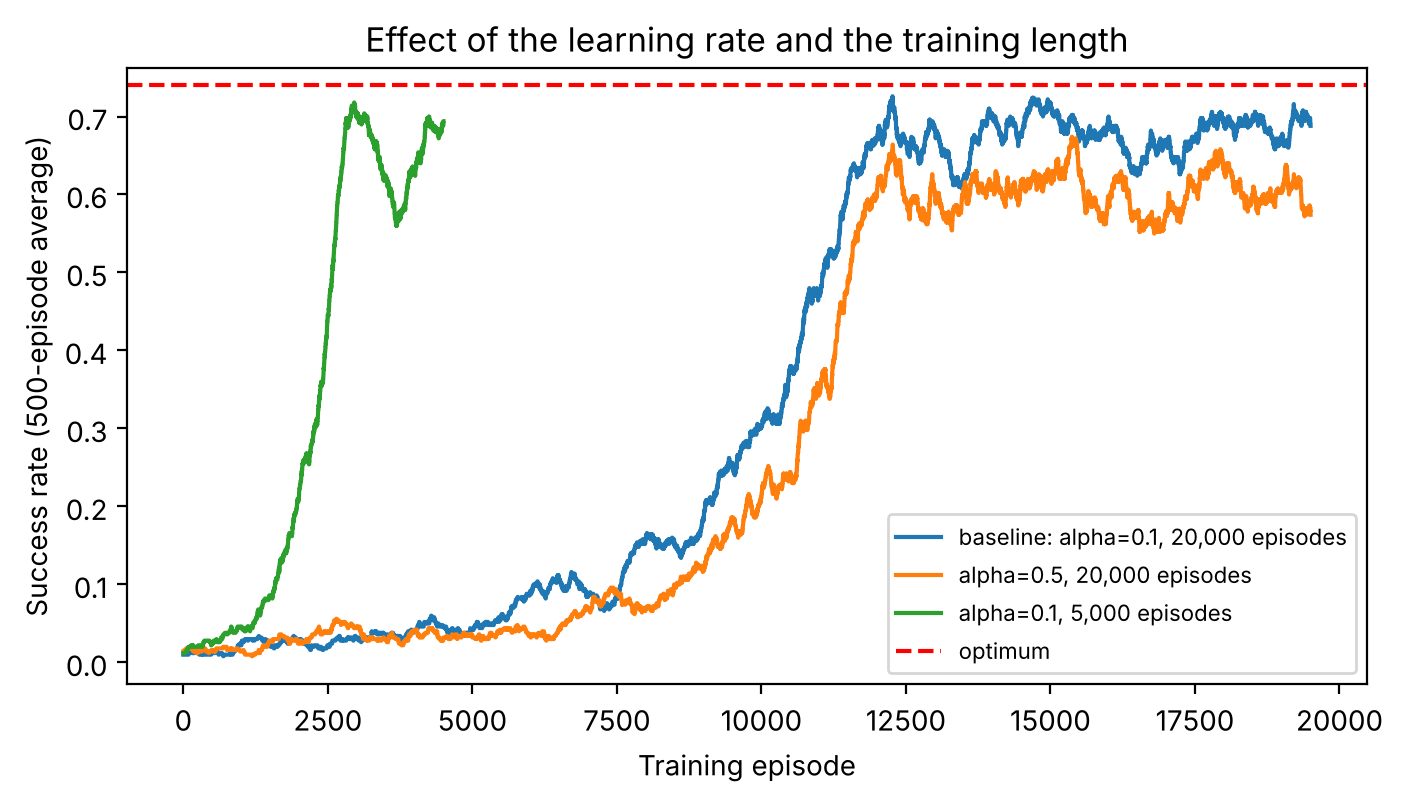

baseline: alpha=0.1, 20,000 episodes
  ← ↑ ↑ ↑
  ← H ← H
  ↑ ↓ ← H
  H → ↓ G
alpha=0.5, 20,000 episodes
  ← ↑ ↑ ↑
  ← H → H
  ↑ ↓ ← H
  H → ← G
alpha=0.1, 5,000 episodes
  ← ↑ ↑ ↑
  ← H ← H
  ↑ ↓ ← H
  H → ↓ G


In [3]:
V_opt, pi_opt, _ = value_iteration(P, n_states, n_actions)     # the optimal policy, as the reference
opt_rate = evaluate_policy(lake, pi_opt)                         # its success rate (the ceiling)

settings = {                                                     # the three agents to compare
    "baseline: alpha=0.1, 20,000 episodes": dict(alpha=0.1, episodes=20000),
    "alpha=0.5, 20,000 episodes": dict(alpha=0.5, episodes=20000),
    "alpha=0.1, 5,000 episodes": dict(alpha=0.1, episodes=5000),
}
runs = {}                                                        # results of each agent
for name, kw in settings.items():                                # train each agent
    t0 = time.time()                                             # timer
    Q, rew, _ = q_learning(make_lake(True), **kw)                # train on a fresh slippery lake
    pol = np.argmax(Q, axis=1)                                   # greedy policy
    agree = np.mean([pol[s] == pi_opt[s] for s in range(16) if desc.flat[s] not in "HG"])  # match with optimum
    runs[name] = dict(Q=Q, rew=rew, pol=pol, rate=evaluate_policy(lake, pol), agree=agree)
    print(f"{name:<38} greedy success = {runs[name]['rate']:.1%} | agreement with optimum = {agree:.0%} "
          f"| Q(start) = {np.round(Q[0], 3)} | {time.time() - t0:.0f} s")
print(f"{'value-iteration optimum':<38} success = {opt_rate:.1%}")

window = 500                                                     # moving-average window
for name, r in runs.items():                                     # one learning curve per agent
    plt.plot(np.convolve(r["rew"], np.ones(window) / window, mode="valid"), label=name)
plt.axhline(opt_rate, color="red", ls="--", label="optimum")     # the ceiling
plt.xlabel("Training episode"); plt.ylabel("Success rate (500-episode average)")
plt.title("Effect of the learning rate and the training length"); plt.legend(fontsize=8)
plt.show()

for name, r in runs.items():                                     # print each learned policy
    print(name); show_policy(r["pol"], desc)

#### Reading the output

| Agent | Greedy success | Agreement with optimum | Training time |
|---|---|---|---|
| Baseline: $\alpha = 0.1$, 20,000 episodes | **74.1%** | 100% | 8 s |
| $\alpha = 0.5$, 20,000 episodes | **0.0%** | 82% | 9 s |
| $\alpha = 0.1$, 5,000 episodes | **74.1%** | 100% | 2 s |
| Value-iteration optimum | 74.1% | | |

**1. A large learning rate ($\alpha = 0.5$) broke the policy completely.**
* **The curve:** a faster learning rate did **not** mean faster progress. The orange curve rises slightly *later* than the baseline and levels off lower, at about 55% to 65% instead of about 70%. Each update moves a Q-value half-way to the latest target, so every single lucky or unlucky slip shifts the estimates a lot, and the table never settles.
* **Why the greedy success is exactly 0%:** the learned policy differs from the optimum in two cells, and one of them is fatal. In **state 14** it chose ← instead of ↓. The goal (state 15) can only be entered from state 14, and from 14 the action ← can move the agent left (to 13), up (to 10) or down (into the wall, staying in 14), but **never right into the goal**. Meanwhile state 13 sends the agent back to 14 with →. The agent loops between 13 and 14 until the 100-step limit, so not a single episode succeeds.
* **The Q-values show why:** the start-state values (0.466, 0.462, 0.466, 0.465) are almost equal and lower than the true value (0.542). With $\alpha = 0.5$ the table keeps chasing the most recent random outcome instead of averaging over many, so close decisions are effectively made by noise.

**2. A shorter run (5,000 episodes) was enough here.** With the same $\alpha = 0.1$, the agent found the same optimal policy (74.1%, 100% agreement) in a quarter of the time. Its start-state Q-values (0.526 against 0.532) are slightly less converged. Its green curve rises much earlier (to about 70% by episode 3,000) because epsilon decays over 3,000 instead of 12,000 episodes, and the dip to about 57% around episode 3,700 shows how noisy a short run can be.

**Answer to the question:** a large $\alpha$ gives a noisier, lower curve and **unreliable values**. On a stochastic problem this can produce a policy that never succeeds. A shorter training run makes the curve rise sooner. Here 5,000 episodes happened to be enough, but with less experience per state the risk of a wrong action in a close call grows, so the result should be checked on more seeds before relying on it.

---
# Exercise 1. The discount factor in Value Iteration

**Question:** re-run Value Iteration with `gamma=0.9`. How do the values and the policy change, and why?

**Approach:** solve the slippery lake with $\gamma = 0.99$ and with $\gamma = 0.9$. Compare the number of sweeps, the value grids and the policies. Then measure each policy's success rate **and how many steps a successful episode takes**, because a smaller $\gamma$ should make the agent more impatient.

gamma = 0.99: 324 sweeps | success = 74.1% | mean steps to goal = 38.3 | timeouts = 9.9%
  values:
[[0.542 0.499 0.471 0.457]
 [0.558 0.    0.358 0.   ]
 [0.592 0.643 0.615 0.   ]
 [0.    0.742 0.863 0.   ]]
  policy:
  ← ↑ ↑ ↑
  ← H ← H
  ↑ ↓ ← H
  H → ↓ G



gamma = 0.9: 85 sweeps | success = 73.3% | mean steps to goal = 37.1 | timeouts = 6.2%
  values:
[[0.069 0.061 0.074 0.056]
 [0.092 0.    0.112 0.   ]
 [0.145 0.247 0.3   0.   ]
 [0.    0.38  0.639 0.   ]]
  policy:
  ← ↑ ← ↑
  ← H ← H
  ↑ ↓ ← H
  H → ↓ G

States whose action changed: [2]
  state 2: ↑ (gamma 0.99)  ->  ← (gamma 0.9)
Ratio V(0.9) / V(0.99) at the start state: 0.127


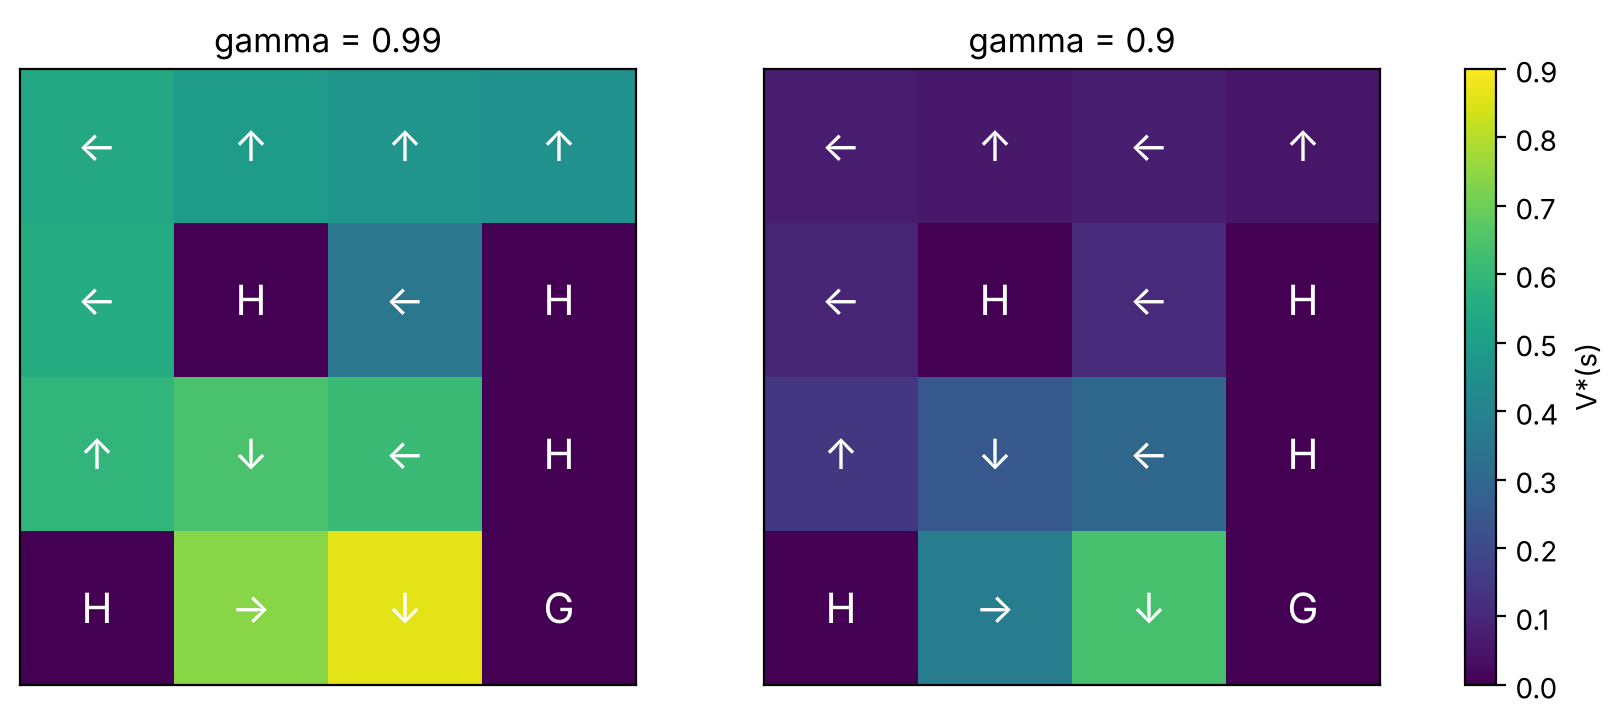

In [4]:
def evaluate_policy_detail(env, policy, episodes=2000, seed=SEED):
    # Success rate, mean steps of successful episodes, and the fraction of episodes cut off at 100 steps
    wins, steps_win, timeouts = 0, [], 0           # counters
    for i in range(episodes):                       # many episodes
        s, _ = env.reset(seed=seed + i)             # new episode
        done, t = False, 0                          # end flag and step counter
        while not done:                             # follow the policy
            s, r, term, trunc, _ = env.step(int(policy[s]))  # act
            t += 1                                  # count the step
            done = term or trunc                    # end of episode
        if r == 1:                                  # reached the goal
            wins += 1; steps_win.append(t)          # record the success and its length
        elif trunc and not term:                    # ran out of time without falling in
            timeouts += 1                           # record a timeout
    return wins / episodes, np.mean(steps_win), timeouts / episodes


results = {}                                        # results for each gamma
for g in [0.99, 0.9]:                               # the two discount factors
    V, pol, sw = value_iteration(P, n_states, n_actions, gamma=g)   # solve the MDP
    rate, steps, tout = evaluate_policy_detail(lake, pol)           # evaluate the policy
    results[g] = dict(V=V, pol=pol, sweeps=sw, rate=rate, steps=steps, tout=tout)
    print(f"gamma = {g}: {sw} sweeps | success = {rate:.1%} | mean steps to goal = {steps:.1f} "
          f"| timeouts = {tout:.1%}")
    print("  values:"); print(np.round(V.reshape(4, 4), 3))
    print("  policy:"); show_policy(pol, desc)
    print()

changed = [s for s in range(16) if desc.flat[s] not in "HG" and results[0.99]["pol"][s] != results[0.9]["pol"][s]]
print("States whose action changed:", changed)                       # where the policies differ
for s in changed:                                                    # describe each change
    print(f"  state {s}: {ARROWS[results[0.99]['pol'][s]]} (gamma 0.99)  ->  {ARROWS[results[0.9]['pol'][s]]} (gamma 0.9)")
print("Ratio V(0.9) / V(0.99) at the start state:", round(results[0.9]["V"][0] / results[0.99]["V"][0], 3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))                       # side-by-side value maps
for ax, g in zip(axes, [0.99, 0.9]):                                  # one map per gamma
    im = ax.imshow(results[g]["V"].reshape(4, 4), cmap="viridis", vmin=0, vmax=0.9)  # same colour scale
    for s in range(16):                                               # label each cell
        r_, c_ = divmod(s, 4)
        lab = desc[r_, c_] if desc[r_, c_] in "HG" else ARROWS[results[g]["pol"][s]]
        ax.text(c_, r_, lab, ha="center", va="center", color="white", fontsize=15)
    ax.set_title(f"gamma = {g}"); ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=axes, label="V*(s)")
plt.show()

#### Reading the output

| | $\gamma = 0.99$ | $\gamma = 0.9$ |
|---|---|---|
| Sweeps to converge | 324 | **85** |
| $V^*$(start) | 0.542 | **0.069** |
| Success rate | 74.1% | 73.3% |
| Mean steps of a successful episode | 38.3 | 37.1 |
| Timeouts (still alive after 100 steps) | 9.9% | **6.2%** |
| Fell into a hole (the remainder) | 16.0% | **20.5%** |
| States whose action changed | | 1 (state 2: ↑ becomes ←) |

**1. The values shrink a lot, especially far from the goal.** With $\gamma = 0.9$ a reward $k$ steps away is worth $0.9^k$. Successful episodes take about 37 steps, and $0.9^{37} \approx 0.02$, so distant states are worth very little. The start value falls to 0.069, only 12.7% of its $\gamma = 0.99$ value. Next to the goal the drop is smaller (state 14: 0.863 becomes 0.639), because the reward there is only a step or two away. The heat map shows this: with $\gamma = 0.9$ only the bottom-right corner stays bright.

**2. Convergence is about 4 times faster (85 against 324 sweeps).** Errors shrink by roughly a factor of $\gamma$ in every sweep, and $0.9$ shrinks them much faster than $0.99$.

**3. The policy barely changes, but its character does.** Only state 2 changes, from ↑ (push into the wall, the safest move) to ← (head back towards the safe left column more directly). With $\gamma = 0.9$ the agent is **more impatient**: waiting is expensive, so it accepts slightly more risk to finish sooner. The numbers confirm this. It times out less often (6.2% against 9.9%) but falls into holes more often (20.5% against 16.0%), and its overall success drops a little (73.3% against 74.1%).

**Answer to the question:** lowering $\gamma$ makes all values smaller, most of all far from the goal, and makes Value Iteration converge faster. The policy becomes slightly more short-sighted: faster, but riskier. **$\gamma$ is part of the problem definition, not only a tuning knob**: it states how much the designer values the future, and a different $\gamma$ can change which behaviour counts as "optimal".

---
# Exercise 2. Q-learning on deterministic ice

**Question:** run Q-learning on `is_slippery=False`. How many episodes are needed, and what success rate is reached?

**Approach:** on deterministic ice every action does exactly what it says, so a single greedy test episode tells us whether the policy works. We train for 1,000 episodes and test the greedy policy every 10 episodes. Then we repeat with smaller training budgets to see the minimum that works.

Value-iteration optimum on deterministic ice: 100%


Training 1,000 episodes took 0.2 s
First training episode that reached the goal: 63
Greedy policy first solves the lake after:    100 episodes
Greedy policy still solves it at the end:     True
Greedy path: 0 -> 4 -> 8 -> 9 -> 10 -> 14 -> 15 (6 steps, reward 1)
Q-values of the start state (Left, Down, Right, Up): [0.911 0.951 0.566 0.879]
0.99 ** 5 = 0.951

Final greedy success for different training budgets (epsilon decays over 60% of each budget):
     50 episodes -> success = 0%


    100 episodes -> success = 0%


    200 episodes -> success = 100%
    300 episodes -> success = 100%
    500 episodes -> success = 100%


   1000 episodes -> success = 100%


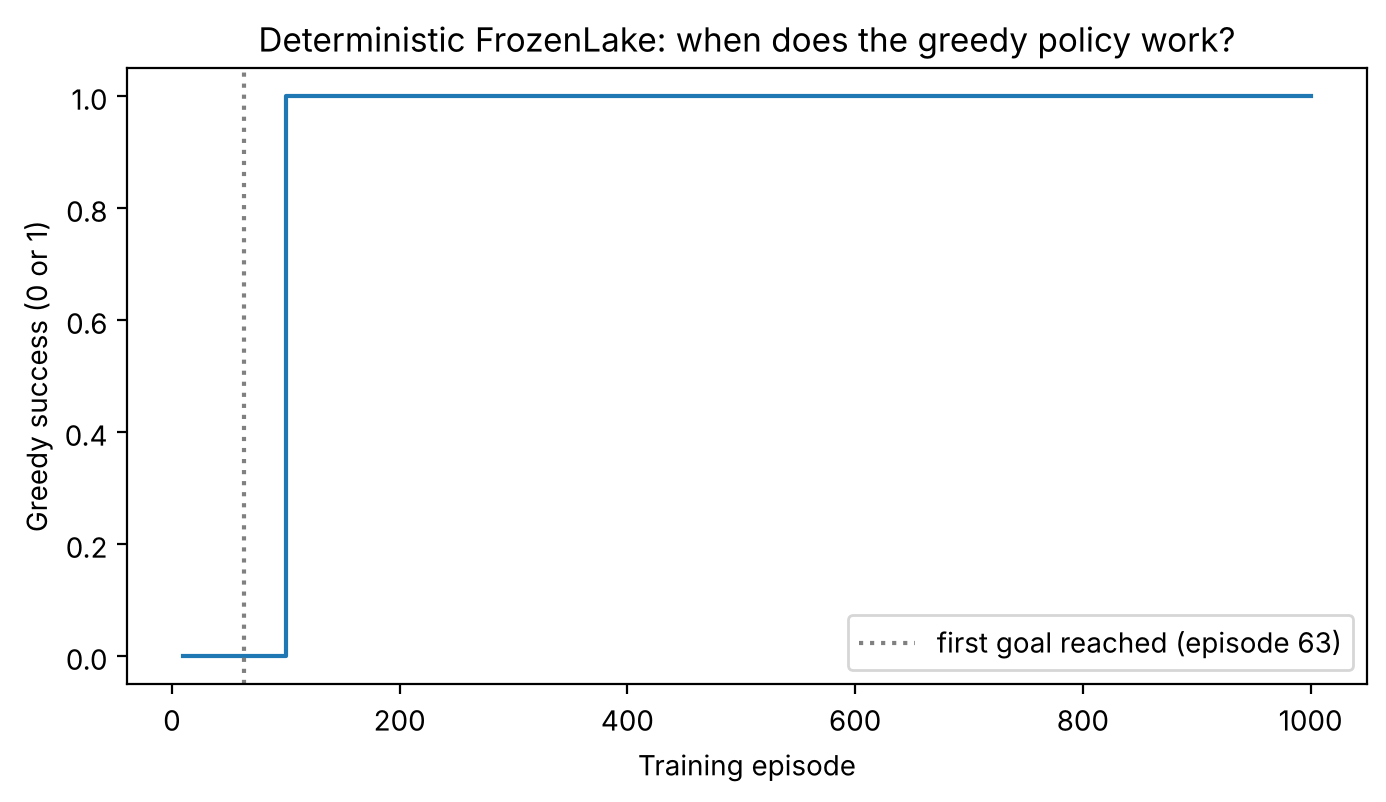

In [5]:
lake_det = make_lake(slippery=False)                               # deterministic lake
V_det, pi_det, _ = value_iteration(lake_det.unwrapped.P, n_states, n_actions)  # its optimum, for reference
print(f"Value-iteration optimum on deterministic ice: {evaluate_policy(lake_det, pi_det, 100):.0%}")

t0 = time.time()                                                    # timer
Q_det, rew_det, hist = q_learning(make_lake(False), episodes=1000,  # train 1,000 episodes ...
                                  eval_env=lake_det, eval_every=10, eval_episodes=1)  # ... test every 10
print(f"Training 1,000 episodes took {time.time() - t0:.1f} s")
first_goal = int(np.argmax(rew_det)) + 1                            # first training episode that reached G
first_solved = next(ep for ep, rate in hist if rate == 1.0)         # first test in which the greedy policy succeeds
print(f"First training episode that reached the goal: {first_goal}")
print(f"Greedy policy first solves the lake after:    {first_solved} episodes")
print(f"Greedy policy still solves it at the end:     {hist[-1][1] == 1.0}")

pol_det = np.argmax(Q_det, axis=1)                                  # final greedy policy
s, _ = lake_det.reset(seed=SEED); path, done = [s], False           # follow it once and record the path
while not done:
    s, r, term, trunc, _ = lake_det.step(int(pol_det[s])); path.append(s); done = term or trunc
print("Greedy path:", " -> ".join(map(str, path)), f"({len(path) - 1} steps, reward {r})")
print("Q-values of the start state (Left, Down, Right, Up):", np.round(Q_det[0], 3))
print("0.99 ** 5 =", round(0.99 ** 5, 3))

print("\nFinal greedy success for different training budgets (epsilon decays over 60% of each budget):")
for n in [50, 100, 200, 300, 500, 1000]:                            # several training budgets
    Qn, _, _ = q_learning(make_lake(False), episodes=n)             # train from scratch
    print(f"  {n:>5} episodes -> success = {evaluate_policy(lake_det, np.argmax(Qn, axis=1), 100):.0%}")

eps_axis, rates = zip(*hist)                                        # unpack the tracking history
plt.step(eps_axis, rates, where="post")                             # greedy success over training
plt.axvline(first_goal, color="grey", ls=":", label=f"first goal reached (episode {first_goal})")
plt.xlabel("Training episode"); plt.ylabel("Greedy success (0 or 1)")
plt.title("Deterministic FrozenLake: when does the greedy policy work?"); plt.legend()
plt.show()

#### Reading the output

**What the numbers say:**
* **The optimum is 100%.** Without slipping, the shortest safe route always works.
* **The first success came in training episode 63.** Before that, every Q-value is 0, so the agent learns nothing: the reward is sparse, and it must stumble onto the goal by random exploration first.
* **The greedy policy first solves the lake by episode 100** (it is tested every 10 episodes, so somewhere between episodes 91 and 100), and it is still correct at the end of training.
* **The greedy path is 0 → 4 → 8 → 9 → 10 → 14 → 15: 6 steps, the shortest possible route.** On deterministic ice there is no reason to hug walls, so the agent simply walks the short path around the holes.
* **The start-state Q-value of Down is 0.951, exactly $0.99^5$.** The reward 1 arrives on the 6th step, so it is discounted 5 times. Q-learning has recovered the exact optimal value.

**Training budgets:** 50 or 100 episodes gave 0%, while 200 or more gave 100%. With a short budget, epsilon falls very quickly (over 60% of the budget), so the agent stops exploring before it has found the goal reliably and propagated the reward back to the start. Once the budget is large enough, success jumps straight to 100%. With no randomness, a policy either works or it does not.

**The plot:** a step function that stays at 0, then jumps to 1 shortly after the first goal is reached (the dotted grey line), and stays there.

**Answer to the question:** on deterministic ice, Q-learning needs only about **100 to 200 episodes** and reaches **100% success** with the shortest 6-step path. On slippery ice it needed about 12,000 episodes to reach 74%. Randomness in the environment makes learning **much slower** (every value must be averaged over many outcomes) and **lowers the best achievable performance**.

---
# Exercise 3. SARSA versus Q-learning

**Question:** change the Q-learning target to use the action actually taken next, $Q(s', a')$, instead of $\max_{a'} Q(s', a')$. Compare the learned policy with Q-learning.

The two updates differ only in the target:

$$\text{Q-learning: } r + \gamma \max_{a'} Q(s', a') \qquad\qquad \text{SARSA: } r + \gamma\, Q(s', a'), \quad a' \text{ chosen by the same } \varepsilon\text{-greedy policy}$$

* **Q-learning** is **off-policy**: it learns the value of the *greedy* policy, whatever the agent actually does.
* **SARSA** (State, Action, Reward, next State, next Action) is **on-policy**: it learns the value of the policy it is *actually following, exploration included*. If exploration is risky, SARSA's values include that risk.

**Approach:** one function implements both, differing in one line. We compare them on slippery FrozenLake (the exercise), and then on **CliffWalking**, the textbook problem where the difference becomes visible.

Q-learning greedy success = 74.1% | Q(start) = [0.541 0.517 0.507 0.507] | training success (last 2,000) = 69.5% | 8 s


SARSA      greedy success = 72.9% | Q(start) = [0.449 0.425 0.441 0.433] | training success (last 2,000) = 66.2% | 7 s
optimum    success = 74.1%
Policies agree on 82% of non-terminal states
Q-learning policy:
  ← ↑ ↑ ↑
  ← H ← H
  ↑ ↓ ← H
  H → ↓ G
SARSA policy:
  ← ↑ ← ↑
  ← H → H
  ↑ ↓ ← H
  H → ↓ G


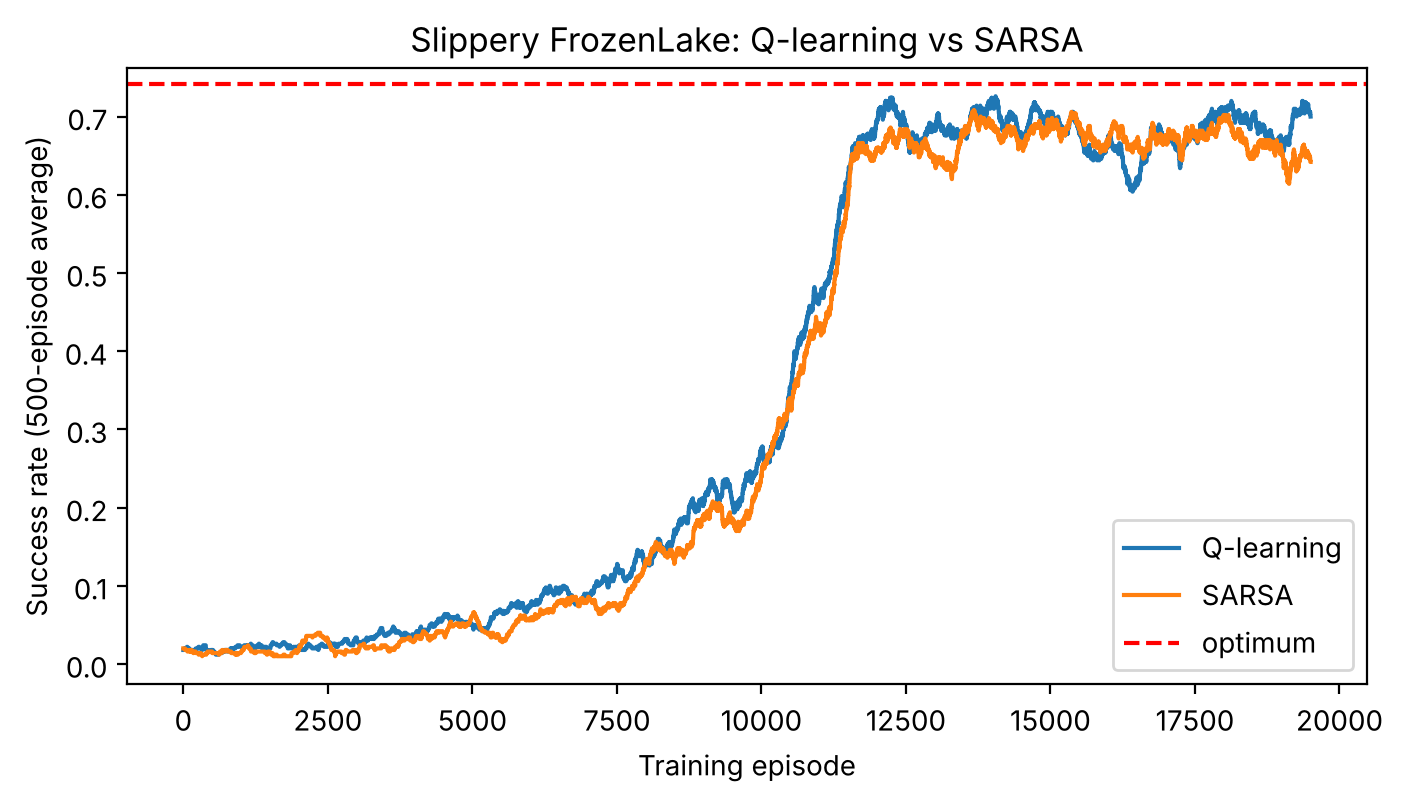

In [6]:
def td_control(env, method, episodes=20000, alpha=0.1, gamma=0.99, eps_start=1.0, eps_end=0.01,
               eps_decay_frac=0.6, seed=SEED):
    # Tabular TD control: method="q" for Q-learning, method="sarsa" for SARSA. Returns Q and episode returns
    rng = np.random.default_rng(seed)               # random generator for exploration
    nS, nA = env.observation_space.n, env.action_space.n
    Q = np.zeros((nS, nA))                          # Q-table
    returns = np.zeros(episodes)                    # sum of rewards of each episode
    decay = max(1, int(eps_decay_frac * episodes))  # episodes over which epsilon decays

    def act(s, eps):                                # epsilon-greedy action selection
        if rng.random() < eps:
            return int(rng.integers(nA))            # explore
        return int(rng.choice(np.flatnonzero(Q[s] == Q[s].max())))  # exploit, random tie-break

    for ep in range(episodes):
        eps = max(eps_end, eps_start - (eps_start - eps_end) * ep / decay)  # current epsilon
        s, _ = env.reset(seed=seed + ep)            # new episode
        a = act(s, eps)                             # first action
        done, G = False, 0.0
        while not done:
            s2, r, term, trunc, _ = env.step(a)     # act
            a2 = act(s2, eps)                       # the next action the agent WILL take
            if method == "q":
                next_value = np.max(Q[s2])          # Q-learning: value of the best next action
            else:
                next_value = Q[s2, a2]              # SARSA: value of the action actually chosen next
            Q[s, a] += alpha * (r + gamma * next_value * (not term) - Q[s, a])   # TD update
            s, a = s2, a2                           # move on (SARSA uses a2 as its next action)
            G += r                                  # accumulate the return
            done = term or trunc
        returns[ep] = G
    return Q, returns


fl = {}                                             # FrozenLake results
for m in ["q", "sarsa"]:                            # train both methods with identical settings
    t0 = time.time()
    Qm, retm = td_control(make_lake(True), m)
    pol = np.argmax(Qm, axis=1)
    fl[m] = dict(Q=Qm, ret=retm, pol=pol, rate=evaluate_policy(lake, pol))
    print(f"{'Q-learning' if m == 'q' else 'SARSA':<10} greedy success = {fl[m]['rate']:.1%} | "
          f"Q(start) = {np.round(Qm[0], 3)} | training success (last 2,000) = {retm[-2000:].mean():.1%} "
          f"| {time.time() - t0:.0f} s")
print(f"{'optimum':<10} success = {opt_rate:.1%}")
same = np.mean([fl['q']['pol'][s] == fl['sarsa']['pol'][s] for s in range(16) if desc.flat[s] not in "HG"])
print(f"Policies agree on {same:.0%} of non-terminal states")
for m in ["q", "sarsa"]:
    print("Q-learning policy:" if m == "q" else "SARSA policy:"); show_policy(fl[m]["pol"], desc)

for m, lab in [("q", "Q-learning"), ("sarsa", "SARSA")]:
    plt.plot(np.convolve(fl[m]["ret"], np.ones(500) / 500, mode="valid"), label=lab)
plt.axhline(opt_rate, color="red", ls="--", label="optimum")
plt.xlabel("Training episode"); plt.ylabel("Success rate (500-episode average)")
plt.title("Slippery FrozenLake: Q-learning vs SARSA"); plt.legend(); plt.show()

#### Reading the output

| | Q-learning | SARSA |
|---|---|---|
| Greedy success (2,000 test episodes) | **74.1%** (the optimum) | 72.9% |
| Q-values of the start state | 0.541, 0.517, 0.507, 0.507 | 0.449, 0.425, 0.441, 0.433 |
| Success during the last 2,000 training episodes (with ε = 0.01) | 69.5% | 66.2% |

**1. Both methods learn a good policy.** They agree on 82% of the non-terminal states (9 of 11). The two differences are:
* **State 2:** SARSA chooses ← instead of ↑. This is a slightly faster but less wall-protected move, the same change that $\gamma = 0.9$ produced in Exercise 1.
* **State 6:** SARSA chooses → instead of ←. These two actions are equally risky here: each has a 1/3 chance of a slip into a neighbouring hole. So this difference does not matter.

The policies end only 1.2 percentage points apart, which is within the margin of error of the test (about ±2 points).

**2. SARSA's values are systematically lower (0.449 against 0.541 at the start).** Q-learning's target uses the **best** next action, so it estimates the value of the perfect greedy policy. SARSA's target uses the action **actually taken**, including the random exploratory actions taken while epsilon was large. Its values therefore include the cost of those mistakes, and they converge only slowly as epsilon falls.

**3. The curves are similar.** On FrozenLake, exploration is not especially dangerous compared with the ice itself, and epsilon decays to 0.01, so the two methods end up nearly the same.

**Answer to the question:** on slippery FrozenLake, SARSA learns almost the same policy as Q-learning, with **lower, more cautious value estimates**. The difference becomes clear only when exploration itself is dangerous, as the next cell shows.

### Where the difference shows: CliffWalking

**CliffWalking** is a 4×12 grid. The agent starts at the bottom-left (S) and must reach the bottom-right (G). The cells between them along the bottom row are a **cliff**: stepping into it gives a reward of -100 and sends the agent back to the start. Every other step gives -1. The shortest path runs right along the edge of the cliff.

We keep exploration **fixed at ε = 0.1** (the agent never stops exploring), use $\alpha = 0.5$ and $\gamma = 1$, and train each method for 500 episodes.

Q-learning: mean return while training (last 100 episodes, with exploration) = -39.1
Q-learning: greedy path return = -13 (13 steps)
  . . . . . . . . . . . .
  . . . . . . . . . . . .
  * * * * * * * * * * * *
  S C C C C C C C C C C G

SARSA: mean return while training (last 100 episodes, with exploration) = -21.6
SARSA: greedy path return = -17 (17 steps)
  * * * * * * * * * * * *
  * . . . . . . . . . . *
  * . . . . . . . . . . *
  S C C C C C C C C C C G



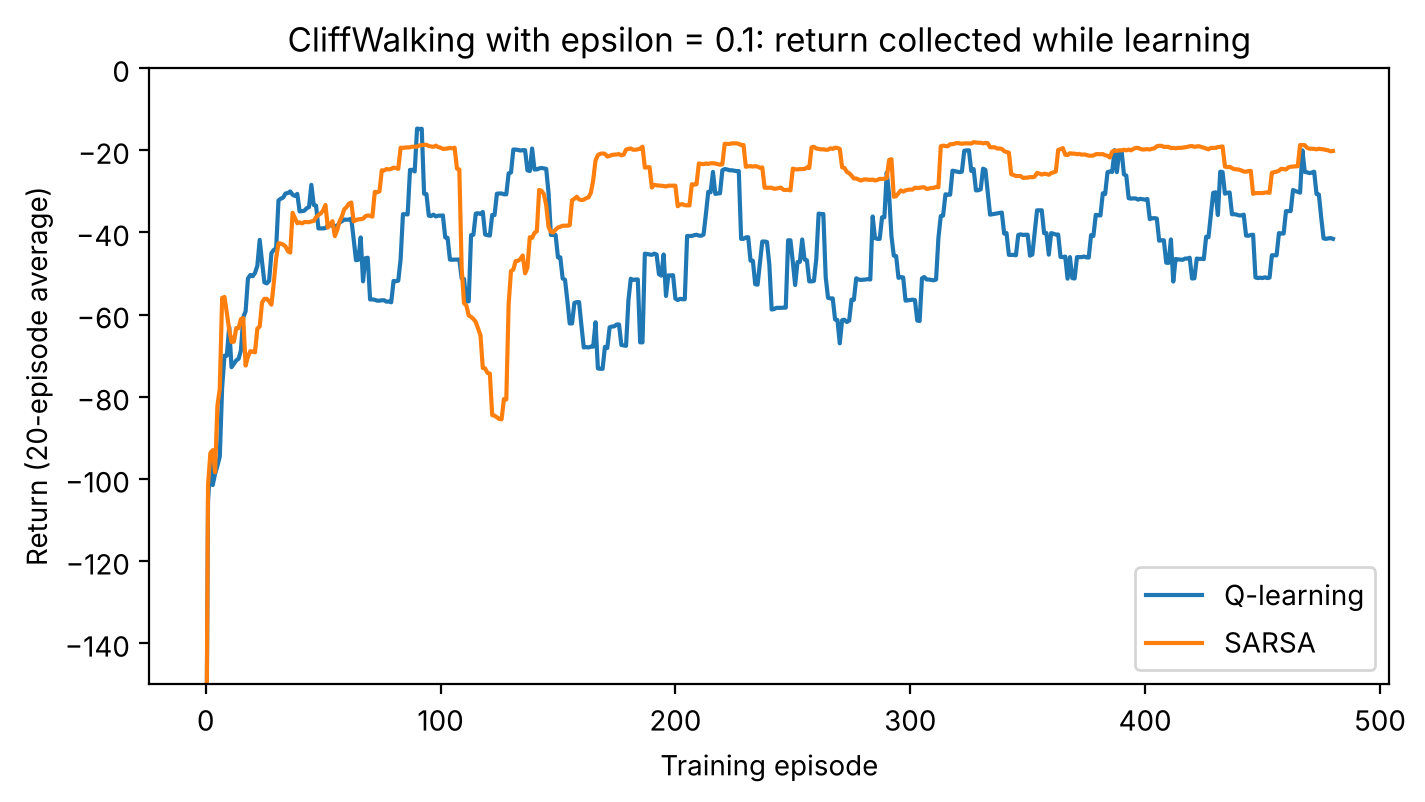

In [7]:
cliff = gym.make("CliffWalking-v1")                 # 4 x 12 grid, 48 states, 4 actions (0 Up, 1 Right, 2 Down, 3 Left)
CLIFF_ARROWS = np.array(["↑", "→", "↓", "←"])       # arrows for CliffWalking actions

def greedy_path(Q, env, max_steps=100):
    # Follow the greedy policy from the start; return the visited states and the return
    s, _ = env.reset(seed=SEED); path, G = [s], 0.0
    for _ in range(max_steps):
        s, r, term, trunc, _ = env.step(int(np.argmax(Q[s]))); path.append(s); G += r
        if term or trunc:
            break
    return path, G

def draw_path(path):
    # Text map: S start, G goal, C cliff, * cells on the greedy path, . other cells
    grid = np.full((4, 12), ".")
    grid[3, 1:11] = "C"
    for s in path:
        r_, c_ = divmod(s, 12)
        if grid[r_, c_] == ".":
            grid[r_, c_] = "*"
    grid[3, 0], grid[3, 11] = "S", "G"
    for row in grid:
        print("  " + " ".join(row))

cw = {}
for m in ["q", "sarsa"]:                            # same settings for both methods
    Qc, retc = td_control(cliff, m, episodes=500, alpha=0.5, gamma=1.0, eps_start=0.1, eps_end=0.1)
    path, G = greedy_path(Qc, cliff)
    cw[m] = dict(Q=Qc, ret=retc, path=path, G=G)
    name = "Q-learning" if m == "q" else "SARSA"
    print(f"{name}: mean return while training (last 100 episodes, with exploration) = {retc[-100:].mean():.1f}")
    print(f"{name}: greedy path return = {G:.0f} ({len(path) - 1} steps)")
    draw_path(path)
    print()

for m, lab in [("q", "Q-learning"), ("sarsa", "SARSA")]:
    plt.plot(np.convolve(cw[m]["ret"], np.ones(20) / 20, mode="valid"), label=lab)
plt.ylim(-150, 0)
plt.xlabel("Training episode"); plt.ylabel("Return (20-episode average)")
plt.title("CliffWalking with epsilon = 0.1: return collected while learning"); plt.legend(); plt.show()

#### Reading the output

**The two greedy paths (S start, G goal, C cliff, \* path):**
* **Q-learning** walks along the row **directly above the cliff**: the shortest path, 13 steps, return -13. This is the truly optimal path *if the agent never makes a random move*.
* **SARSA** climbs to the **top row**, as far from the cliff as possible, walks across, and comes down at the end: 17 steps, return -17. The path is longer, but it is safe.

**Return collected while learning (with ε = 0.1, last 100 episodes):**
* **Q-learning: -39.1. SARSA: -21.6.**
* Q-learning's chosen path runs next to the cliff, and 10% of its moves are random, so it sometimes steps off the edge (-100). Its online return is therefore worse, even though its greedy path is shorter.
* The plot shows this. The SARSA curve settles higher (closer to 0), while the Q-learning curve keeps dropping sharply each time it falls.

**Why the methods disagree:** Q-learning learns the value of the **greedy** policy and ignores the fact that it will keep exploring. SARSA learns the value of **what it actually does, random moves included**, so it "knows" that walking beside the cliff while exploring is dangerous, and it keeps its distance.

**Answer to the question:** SARSA is **on-policy and risk-aware**: it prefers policies that stay safe under its own exploration. Q-learning is **off-policy and optimistic**: it finds the best policy for perfect execution, but performs worse while it is still exploring. When mistakes during learning are costly (a real robot, a real vehicle, live operations), this difference matters, and it is a core consideration in **safe RL**.

---
# Exercise 4. Double DQN

**Question:** in `train_dqn`, choose the next action with `q_net` and evaluate it with `target_net`. Does training become more stable?

**Background:** standard DQN uses one network for two jobs in the target, $\max_{a'} Q_{\theta^-}(s', a')$: it **selects** the best next action and also **evaluates** it. Taking the maximum of noisy estimates is biased upwards, because the action whose value happens to be overestimated is the one that gets chosen. This **overestimation** feeds back into the targets. Double DQN (van Hasselt et al., 2016) separates the two jobs:

$$\text{DQN target: } r + \gamma\,(1-\text{done})\, Q_{\theta^-}\big(s', \arg\max_{a'} Q_{\theta^-}(s', a')\big)$$
$$\text{Double DQN target: } r + \gamma\,(1-\text{done})\, Q_{\theta^-}\big(s', \arg\max_{a'} Q_{\theta}(s', a')\big)$$

The **online** network $Q_\theta$ chooses $a'$, and the **target** network $Q_{\theta^-}$ says how good it is. An action is only rated highly if both networks agree that it is good.

**Approach:** the `train_dqn` below is the main notebook's function with three additions: a `double` switch (the only change the exercise asks for), a choice of environment (needed for Exercise 5), and keeping a copy of the **best network** seen during training (the fix suggested in Part 5). We train DQN and Double DQN with the same settings on **two seeds each**, because a single run of DQN is too noisy to support a conclusion.

To measure overestimation we compare, at the start of each test episode, the network's prediction $\max_a Q(s_0, a)$ with the discounted return the agent then actually collects, $\sum_t \gamma^t r_{t+1}$.

In [8]:
class QNetwork(nn.Module):
    # Fully connected network: state in, one Q-value per action out (same as Part 5)
    def __init__(self, state_dim, n_actions, hidden=128):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(state_dim, hidden), nn.ReLU(),
                                 nn.Linear(hidden, hidden), nn.ReLU(),
                                 nn.Linear(hidden, n_actions))
    def forward(self, x):
        return self.net(x)


class ReplayBuffer:
    # Fixed-size memory of past transitions (same as Part 5)
    def __init__(self, capacity):
        self.buffer = deque(maxlen=capacity)
    def push(self, s, a, r, s2, done):
        self.buffer.append((s, a, r, s2, done))
    def sample(self, batch_size):
        s, a, r, s2, d = map(np.array, zip(*random.sample(self.buffer, batch_size)))
        return (torch.tensor(s, dtype=torch.float32), torch.tensor(a, dtype=torch.int64),
                torch.tensor(r, dtype=torch.float32), torch.tensor(s2, dtype=torch.float32),
                torch.tensor(d, dtype=torch.float32))
    def __len__(self):
        return len(self.buffer)


def greedy_episode(q_net, env, seed):
    # One episode with the greedy policy (no exploration); returns its total reward
    s, _ = env.reset(seed=seed); total, done = 0.0, False
    while not done:
        with torch.no_grad():
            a = int(q_net(torch.tensor(s, dtype=torch.float32)).argmax())
        s, r, term, trunc, _ = env.step(a); total += r; done = term or trunc
    return total


def train_dqn(env_id="CartPole-v1", episodes=300, double=False, gamma=0.99, lr=1e-3, batch_size=64,
              buffer_size=50_000, warmup=1_000, eps_start=1.0, eps_end=0.02, eps_decay_steps=10_000,
              target_update=500, seed=SEED, val_every=10, val_episodes=5, val_seed=5000, print_every=50):
    # DQN (double=False) or Double DQN (double=True).
    # Every val_every episodes the greedy policy is tested on validation seeds (5000+, never used for training
    # or testing); the network with the best validation score is kept. Returns final net, best net, returns, best score
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)   # identical start for every variant
    env = gym.make(env_id); env.action_space.seed(seed)
    state_dim, n_act = env.observation_space.shape[0], env.action_space.n
    q_net, target_net = QNetwork(state_dim, n_act), QNetwork(state_dim, n_act)
    target_net.load_state_dict(q_net.state_dict())
    optimizer = optim.Adam(q_net.parameters(), lr=lr)
    buffer = ReplayBuffer(buffer_size)
    returns, total_steps = [], 0
    best_val, best_state = -np.inf, copy.deepcopy(q_net.state_dict())  # best validation score so far
    val_env = gym.make(env_id)                                          # separate environment for validation

    for ep in range(episodes):
        s, _ = env.reset(seed=seed + ep)
        ep_return, done = 0.0, False
        while not done:
            eps = max(eps_end, eps_start - (eps_start - eps_end) * total_steps / eps_decay_steps)
            if random.random() < eps:
                a = env.action_space.sample()
            else:
                with torch.no_grad():
                    a = int(q_net(torch.tensor(s, dtype=torch.float32)).argmax())
            s2, r, term, trunc, _ = env.step(a)
            buffer.push(s, a, r, s2, float(term))     # only true terminations count as "done"
            s, ep_return, total_steps = s2, ep_return + r, total_steps + 1
            done = term or trunc

            if len(buffer) >= warmup:
                bs, ba, br, bs2, bd = buffer.sample(batch_size)
                q_sa = q_net(bs).gather(1, ba.unsqueeze(1)).squeeze(1)
                with torch.no_grad():
                    if double:                                              # ---- Double DQN ----
                        next_a = q_net(bs2).argmax(1, keepdim=True)         # online network SELECTS a'
                        next_q = target_net(bs2).gather(1, next_a).squeeze(1)  # target network EVALUATES it
                    else:                                                   # ---- standard DQN ----
                        next_q = target_net(bs2).max(1).values              # target network does both
                    target = br + gamma * (1 - bd) * next_q
                loss = nn.functional.smooth_l1_loss(q_sa, target)
                optimizer.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(q_net.parameters(), 10)
                optimizer.step()

            if total_steps % target_update == 0:
                target_net.load_state_dict(q_net.state_dict())

        returns.append(ep_return)
        if val_every and (ep + 1) % val_every == 0:                         # periodic greedy validation
            val = np.mean([greedy_episode(q_net, val_env, val_seed + i) for i in range(val_episodes)])
            if val > best_val:                                              # new best network
                best_val, best_state = val, copy.deepcopy(q_net.state_dict())  # keep a copy of its weights
        if print_every and (ep + 1) % print_every == 0:
            print(f"  episode {ep + 1:4d} | mean return (last {print_every}) = "
                  f"{np.mean(returns[-print_every:]):7.1f} | epsilon = {eps:.2f}")

    best_net = QNetwork(state_dim, n_act); best_net.load_state_dict(best_state)
    return q_net, best_net, returns, best_val


def evaluate_dqn(q_net, env_id="CartPole-v1", episodes=20, seed=1000, gamma=0.99):
    # Greedy test episodes on unseen seeds. Returns: returns, predicted max Q(s0), actual discounted returns
    env = gym.make(env_id)
    rets, q0s, disc = [], [], []
    for i in range(episodes):
        s, _ = env.reset(seed=seed + i)
        with torch.no_grad():
            q0s.append(float(q_net(torch.tensor(s, dtype=torch.float32)).max()))  # predicted value of s0
        total, g, t, done = 0.0, 0.0, 0, False
        while not done:
            with torch.no_grad():
                a = int(q_net(torch.tensor(s, dtype=torch.float32)).argmax())
            s, r, term, trunc, _ = env.step(a)
            total += r; g += (gamma ** t) * r; t += 1
            done = term or trunc
        rets.append(total); disc.append(g)
    return np.array(rets), np.array(q0s), np.array(disc)

DQN        seed 42


  episode   50 | mean return (last 50) =    24.8 | epsilon = 0.88


  episode  100 | mean return (last 50) =    22.2 | epsilon = 0.77


  episode  150 | mean return (last 50) =    30.4 | epsilon = 0.62


  episode  200 | mean return (last 50) =    60.4 | epsilon = 0.32


  episode  250 | mean return (last 50) =   125.7 | epsilon = 0.02


... (18 outputs left out)

  episode  200 | mean return (last 50) =    67.5 | epsilon = 0.27


  episode  250 | mean return (last 50) =    66.2 | epsilon = 0.02


  episode  300 | mean return (last 50) =    92.7 | epsilon = 0.02


  done in 23 s

run                 best val score  last 50 eps  drop after peak   test: final net   test: best net  Q(s0) pred   actual  overest.
DQN        seed 42           148.4        139.9             11.0      110.5 ±  2.6     134.2 ± 60.5        33.7     67.0     -33.3
DQN        seed 7            167.2        117.6              7.7      106.0 ±  7.5     216.8 ± 80.2        30.8     65.5     -34.6
Double DQN seed 42           165.4         92.9              0.0      140.6 ± 12.2     167.9 ± 36.0        23.2     75.5     -52.3
Double DQN seed 7            390.4         92.7              7.9       84.8 ± 14.9     243.8 ±150.4        26.1     56.7     -30.6


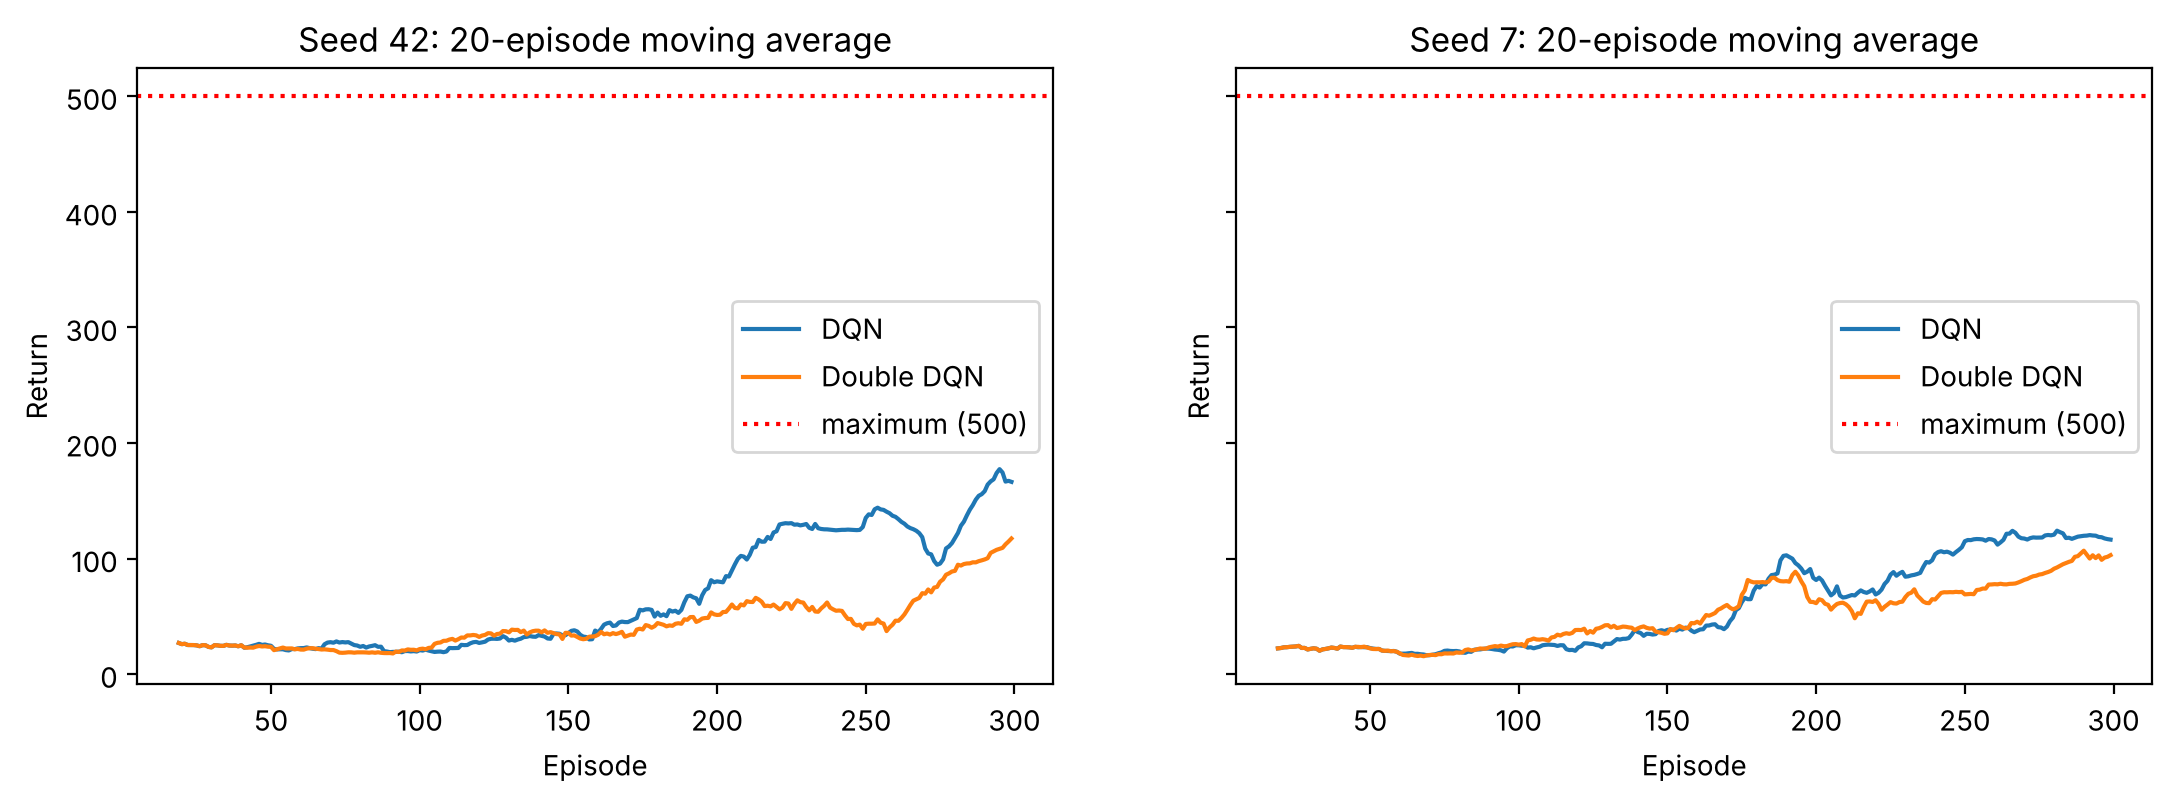

In [9]:
dqn_runs = {}                                                      # results of the four training runs
for double in [False, True]:                                       # standard DQN, then Double DQN
    for seed in [42, 7]:                                           # two seeds each
        name = f"{'Double DQN' if double else 'DQN':<10} seed {seed}"
        print(name)
        t0 = time.time()
        final_net, best_net, rets, best_avg = train_dqn(double=double, seed=seed)
        r_final, q0, disc = evaluate_dqn(final_net)                # test the final network
        r_best, _, _ = evaluate_dqn(best_net)                      # test the best checkpoint
        smooth = np.convolve(rets, np.ones(20) / 20, mode="valid")
        peak = int(np.argmax(smooth))
        dqn_runs[name] = dict(rets=rets, smooth=smooth, best_avg=best_avg,
                              final_mean=r_final.mean(), final_std=r_final.std(), best_mean=r_best.mean(),
                              best_std=r_best.std(), last50=np.mean(rets[-50:]),
                              drop=smooth[peak] - smooth[peak:].min(),
                              overest=np.mean(q0 - disc), q0=q0.mean(), disc=disc.mean(),
                              minutes=(time.time() - t0) / 60)
        print(f"  done in {time.time() - t0:.0f} s\n")

print(f"{'run':<19}{'best val score':>15}{'last 50 eps':>13}{'drop after peak':>17}"
      f"{'test: final net':>18}{'test: best net':>17}{'Q(s0) pred':>12}{'actual':>9}{'overest.':>10}")
for name, d in dqn_runs.items():
    print(f"{name:<19}{d['best_avg']:>15.1f}{d['last50']:>13.1f}{d['drop']:>17.1f}"
          f"{d['final_mean']:>11.1f} ±{d['final_std']:>5.1f}{d['best_mean']:>10.1f} ±{d['best_std']:>5.1f}"
          f"{d['q0']:>12.1f}{d['disc']:>9.1f}{d['overest']:>10.1f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, seed in zip(axes, [42, 7]):
    for name, d in dqn_runs.items():
        if name.endswith(f"seed {seed}"):
            ax.plot(range(19, 19 + len(d["smooth"])), d["smooth"], label=name.split(" seed")[0].strip())
    ax.axhline(500, color="red", ls=":", label="maximum (500)")
    ax.set(title=f"Seed {seed}: 20-episode moving average", xlabel="Episode", ylabel="Return")
    ax.legend()
plt.show()

#### Reading the output

The table compares four 300-episode runs. "Best val score" is the mean greedy return on 5 validation seeds of the best network found during training; "test" columns use 20 unseen seeds (1000 to 1019).

| Run | Final 50 training episodes | Test: final network | Test: best (validated) network | $Q(s_0)$ predicted | Actual discounted return |
|---|---|---|---|---|---|
| DQN, seed 42 | 139.9 | 110.5 ± 2.6 | 134.2 ± 60.5 | 33.7 | 67.0 |
| DQN, seed 7 | 117.6 | 106.0 ± 7.5 | 216.8 ± 80.2 | 30.8 | 65.5 |
| Double DQN, seed 42 | 92.9 | **140.6** ± 12.2 | 167.9 ± 36.0 | 23.2 | 75.5 |
| Double DQN, seed 7 | 92.7 | 84.8 ± 14.9 | **243.8** ± 150.4 | 26.1 | 56.7 |

**1. Learning speed.** In the progress lines and the curves, standard DQN rises a little earlier (about 126 to 140 by the end, against about 93 for Double DQN). Double DQN's more conservative targets often make early learning **slower**, and that is visible here.

**2. Stability.** The "drop after peak" column is small for all four runs (0 to 11). Within 300 episodes none of the agents reached the high plateau where DQN usually collapses (Part 5 of the main notebook showed such a collapse), so **this run cannot show a stability gain**. In longer trial runs of 500 episodes made while preparing this solution, **both** variants showed large collapses after a peak, on different seeds. Double DQN did not remove the instability.

**3. Test performance.** The best result with the final network was Double DQN on seed 42 (140.6), but the worst was Double DQN on seed 7 (84.8). The two seeds of the same method differ as much as the two methods do. With two seeds, **neither method is clearly better**.

**4. Overestimation.** In every run the predicted $Q(s_0)$ is **lower** than the discounted return actually collected (for example 33.7 against 67.0), so these short runs show **underestimation**, not overestimation. The value estimates are still catching up, because the targets are refreshed only every 500 steps. Double DQN's predictions are lower still (23 to 26 against 31 to 34), which is consistent with it removing the upward bias of the max. But that bias is not the main source of error at this stage of training.

**5. A side result: the validated checkpoint helps.** In all four runs the best network chosen on validation seeds scored higher on the test seeds than the final network (for example 243.8 against 84.8). Keeping the network that validates best is a cheap and effective fix for DQN's ups and downs. It must be chosen on seeds that are **separate from the test seeds**, or the test result would be optimistic.

**Answer to the question:** in this experiment, Double DQN learned a little more slowly and did **not** become measurably more stable. Its main benefit, reducing overestimation, matters most in long training runs and in problems with many actions or noisy rewards (it was introduced for Atari games). The broader lesson: in Deep RL, the difference between two random seeds is often as large as the difference between two algorithms. **A claim that one method is "more stable" needs many seeds (typically 5 to 10 or more), confidence intervals, and a held-out test.**

---
# Exercise 5. DQN on a new environment: Acrobot

**Acrobot-v1** is a two-link pendulum hanging from a fixed pivot, like an arm with a shoulder and an elbow. Only the elbow joint has a motor. The goal is to swing the tip of the lower link above a line that is one link-length above the pivot.

| Item | Value |
|---|---|
| State | 6 numbers: $\cos\theta_1, \sin\theta_1, \cos\theta_2, \sin\theta_2$ and the two angular velocities |
| Actions | 3: apply torque -1, 0 or +1 at the elbow |
| Reward | -1 for every step until the goal is reached (0 on the final step) |
| Episode end | goal reached (**terminated**) or 500 steps (**truncated**) |

The return is minus the number of steps taken, so **higher (closer to 0) is better**, and -500 means the agent never reached the goal. The same `train_dqn` works unchanged: only the environment name changes, and the network sizes adapt automatically to 6 inputs and 3 outputs.

**One change from CartPole:** `target_update` is set to 100 instead of 500. In a trial run with the default 500, training returns reached about -150, but the frozen greedy network **failed every test episode (-500)**. All three of its Q-values were almost equal (about -41.4 to -41.6), so the greedy policy always applied the same torque and never built up a swing. The agent had only appeared to work during training, because the network was changing at every step. Syncing the target network more often lets the value estimates follow the true returns more closely, and the greedy policy then works.

Observation space: (6,) | Action space: Discrete(3)


Random agent over 20 episodes: mean = -496.4, best = -427, worst = -500

Training DQN on Acrobot-v1:


  episode   25 | mean return (last 25) =  -300.0 | epsilon = 0.26


  episode   50 | mean return (last 25) =  -118.8 | epsilon = 0.02


  episode   75 | mean return (last 25) =  -105.3 | epsilon = 0.02


  episode  100 | mean return (last 25) =  -100.0 | epsilon = 0.02


  episode  125 | mean return (last 25) =   -92.8 | epsilon = 0.02


  episode  150 | mean return (last 25) =   -89.0 | epsilon = 0.02
Training took 34 s | best validation score = -83.2
Test, final network: mean = -83.8 ± 42.5, reached goal in 100% of 20 episodes, returns = [-74, -74, -81, -71, -95, -77, -70, -81, -84, -266, -80, -62, -72, -77, -69, -72, -62, -63, -72, -74]


Test, best network : mean = -83.8 ± 42.5, reached goal in 100% of 20 episodes, returns = [-74, -74, -81, -71, -95, -77, -70, -81, -84, -266, -80, -62, -72, -77, -69, -72, -62, -63, -72, -74]


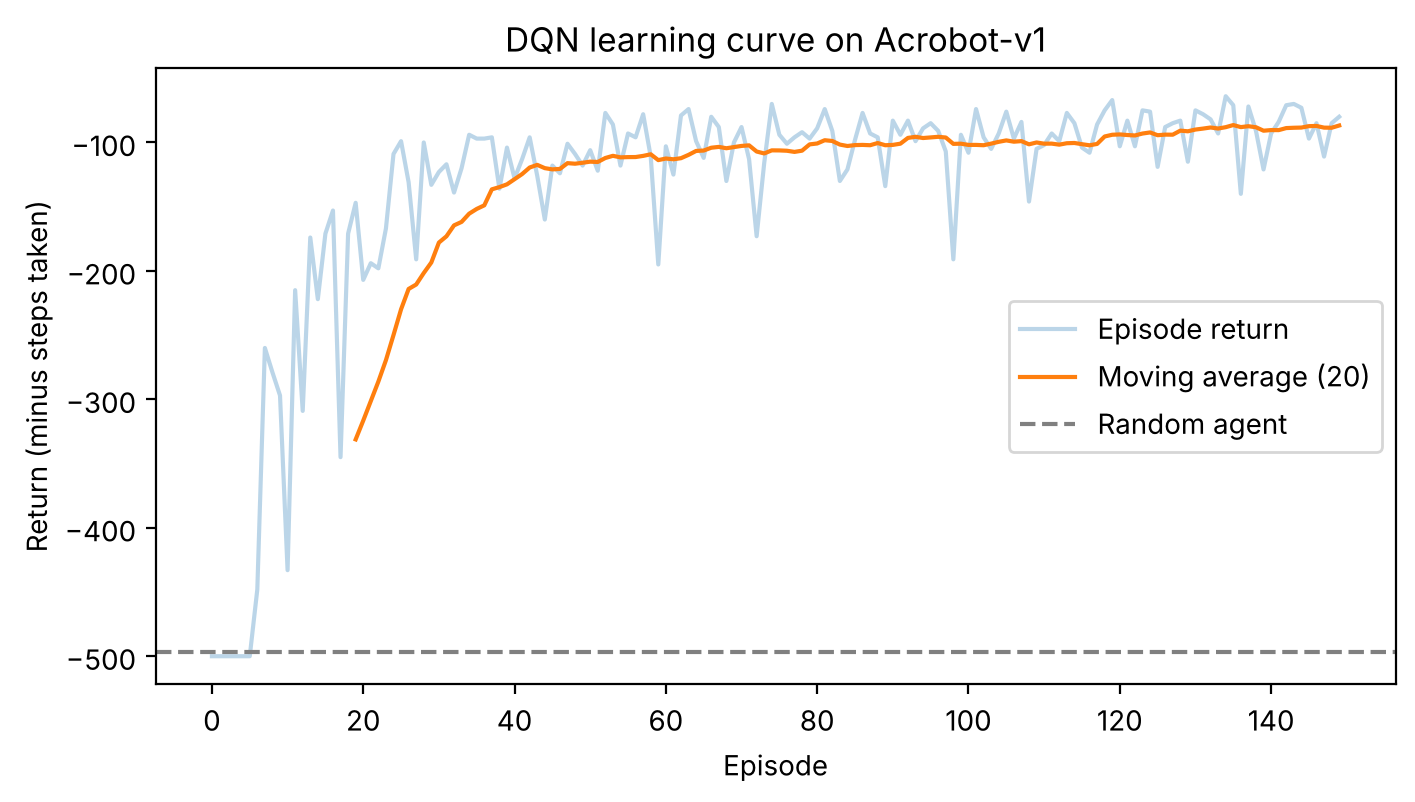

In [10]:
acro = gym.make("Acrobot-v1")                                       # the new environment
print("Observation space:", acro.observation_space.shape, "| Action space:", acro.action_space)
acro.action_space.seed(SEED)
rand_ret = []                                                       # random baseline
for i in range(20):
    s, _ = acro.reset(seed=1000 + i); total, done = 0.0, False
    while not done:
        s, r, term, trunc, _ = acro.step(acro.action_space.sample()); total += r; done = term or trunc
    rand_ret.append(total)
print(f"Random agent over 20 episodes: mean = {np.mean(rand_ret):.1f}, best = {max(rand_ret):.0f}, "
      f"worst = {min(rand_ret):.0f}")

print("\nTraining DQN on Acrobot-v1:")
t0 = time.time()
acro_final, acro_best, acro_rets, acro_best_avg = train_dqn("Acrobot-v1", episodes=150, target_update=100,
                                                            seed=SEED, print_every=25)  # faster target sync (see text)
print(f"Training took {time.time() - t0:.0f} s | best validation score = {acro_best_avg:.1f}")

for label, net in [("final network", acro_final), ("best network ", acro_best)]:
    r_test, _, _ = evaluate_dqn(net, "Acrobot-v1")
    print(f"Test, {label}: mean = {r_test.mean():.1f} ± {r_test.std():.1f}, "
          f"reached goal in {np.mean(r_test > -500):.0%} of 20 episodes, returns = {[int(x) for x in r_test]}")

plt.plot(acro_rets, alpha=0.3, label="Episode return")
plt.plot(range(19, len(acro_rets)), np.convolve(acro_rets, np.ones(20) / 20, mode="valid"), label="Moving average (20)")
plt.axhline(np.mean(rand_ret), color="grey", ls="--", label="Random agent")
plt.xlabel("Episode"); plt.ylabel("Return (minus steps taken)")
plt.title("DQN learning curve on Acrobot-v1"); plt.legend(); plt.show()

#### Reading the output

**What you see:**
* **Random baseline: -496.4** over 20 episodes. Random torques almost never lift the tip above the line: 19 of 20 episodes hit the 500-step limit, and the best one took 427 steps.
* **Training:** the mean return rises from -300.0 (episodes 1 to 25) to -118.8 by episode 50, then improves steadily to -89.0 by episode 150. Epsilon reaches its minimum very early (by episode 50) because the long early episodes use up the 10,000-step decay quickly.
* **Test (20 unseen seeds, no exploration): -83.8 ± 42.5, with the goal reached in 100% of episodes.** That means a swing-up in about 84 steps on average, compared with almost never for the random agent.
* The final and the best validated network are the same here, because validation was highest near the end of training.
* **One outlier:** 19 test episodes take 62 to 95 steps, but one takes 266. Its starting state needed a different swing pattern, and the agent recovered only slowly. The ± 42.5 is mostly this single episode.

**The plot:** the moving average starts near the random line at -500, rises steeply within the first 50 episodes, and then improves slowly towards about -90. The faint line shows occasional slow episodes even late in training.

**Answer to the question:** the same DQN code, unchanged except for the environment name and one hyperparameter, learned to swing up the Acrobot in about 150 episodes (34 s on a CPU). It improved the return from about -496 to about -84, with 100% success on unseen starting states.

**Two lessons for trustworthy deployment:**
1. **Hyperparameters do not transfer automatically.** The CartPole setting `target_update=500` produced an Acrobot agent that looked good during training but failed every test.
2. **Always test the frozen, greedy policy separately from training.** Training curves measure a moving target (a network that changes every step, plus exploration). What you would actually deploy is a fixed network, and it can behave very differently.

---
# Summary of the solutions

| Exercise | Short answer (from this run) |
|---|---|
| 0. Learning rate and training length | $\alpha = 0.5$ learned faster but noisily and produced a policy with **0% success** (a 13 ↔ 14 loop). 5,000 episodes with $\alpha = 0.1$ was enough to reach the optimum of 74.1% |
| 1. $\gamma = 0.9$ in Value Iteration | Values shrink (start: 0.542 → 0.069), convergence is 4× faster (85 vs 324 sweeps), and the policy becomes slightly more impatient (fewer timeouts, more holes, 73.3% vs 74.1%) |
| 2. Deterministic ice | About 100 to 200 episodes give **100% success** along the shortest 6-step path, with $Q = 0.99^5 = 0.951$; slippery ice needed about 12,000 episodes for 74% |
| 3. SARSA | On FrozenLake, almost the same policy (72.9% vs 74.1%) with lower value estimates. On CliffWalking, SARSA takes the **safe** path (-17) and earns more while exploring (-21.6 vs -39.1); Q-learning takes the **edge** path (-13) |
| 4. Double DQN | Slightly slower learning; no measurable stability gain over two seeds and 300 episodes; seed-to-seed variation is as large as the method difference. Selecting the best network on validation seeds helped in all four runs |
| 5. Acrobot | DQN reached **100% success** on unseen starts (-83.8 vs -496.4 random) after changing `target_update` to 100; with the CartPole setting, the greedy policy failed every test |

**Recurring lessons for trustworthy RL:**
1. **Evaluate what you deploy:** test the frozen greedy policy on held-out seeds, not the training curve.
2. **Report variability:** use several seeds, and give the spread, not only the mean.
3. **Keep validation and test separate:** choose checkpoints and hyperparameters on validation data and report on unseen test data.
4. **Account for risk while learning:** on-policy methods such as SARSA trade a little optimality for safety during exploration.